In [1]:
import obspy
import geopandas as gpd
import math
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
import re
from obspy.clients.fdsn.client import Client
import json
from shapely.geometry import LineString
import scipy
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 18}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
import glob
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)
from pyproj import CRS, Transformer
import re

In [2]:
grid_df = pd.read_csv('STATIONS_XGRID_2by2_PSGRID_PNSN_remove_dup',header=None,sep=' ',names=['station','network','lat','lon','elev','elev1'])

In [3]:
grid_df

,station,network,lat,lon,elev,elev1
0,X000000,CZ,40.260250,-127.926390,0.0,0.0
1,X000001,CZ,40.261250,-127.902960,0.0,0.0
2,X000002,CZ,40.262240,-127.879520,0.0,0.0
3,X000003,CZ,40.263230,-127.856090,0.0,0.0
4,X000004,CZ,40.264210,-127.832650,0.0,0.0
...,...,...,...,...,...,...
177556,YELM,UW,46.940160,-122.590810,0.0,0.0
177557,YPT,UW,46.048350,-118.963170,0.0,0.0
177558,HUF,WR,40.044498,-120.885597,0.0,0.0
177559,NS0092,WR,40.190810,-120.552840,0.0,0.0


In [20]:
# Read in cable locations
north = pd.read_csv('RSNcableroute_north_nostubs_withdepths.xy',delim_whitespace=True, header=None, names=['lat','lon','depth'],comment='>')
south = pd.read_csv('RSNcableroute_south_nostubs_withdepths.xy',delim_whitespace=True, header=None, names=['lat','lon','depth'],comment='>')

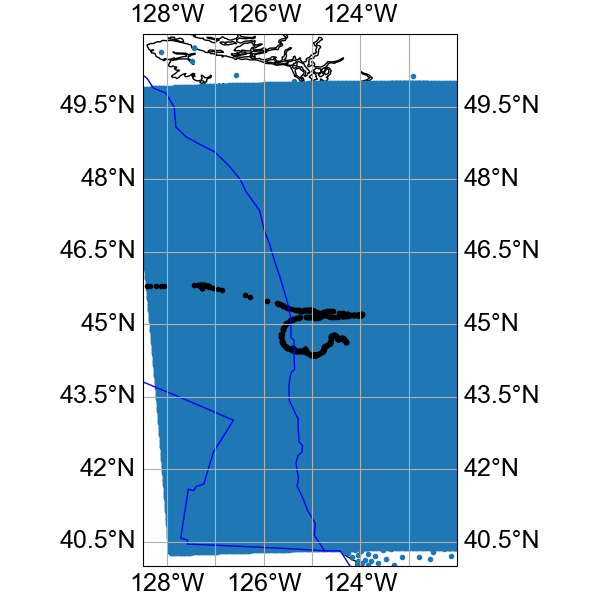

In [21]:
%matplotlib widget

fig = plt.figure(figsize=[6,6],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines()

ax.plot(grid_df.lon,grid_df.lat,'.')
ax.plot(north.lon,north.lat,'k.')
ax.plot(south.lon,south.lat,'k.')

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
ax.set_xlim(-128.5,-122)
ax.set_ylim(40,51)
gl = ax.gridlines(draw_labels=True) 

In [22]:
cable_df = pd.concat([north,south])
cable_df

,lat,lon,depth
0,45.202300,-123.967150,0.0
1,45.200570,-123.978470,10.0
2,45.199420,-123.986030,20.0
3,45.199380,-123.986270,20.0
4,45.198700,-123.990070,23.0
...,...,...,...
304,44.641435,-124.308128,-80.0
305,44.640188,-124.307308,-80.0
306,44.638428,-124.306260,-80.0
307,44.637512,-124.305694,-81.5


In [23]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import LineString


def grid_points_nearest_cable(
    grid_df,
    cable_df,
    grid_lat="lat",
    grid_lon="lon",
    cable_lat="lat",
    cable_lon="lon",
    spacing_m=5000,
    max_distance_m=None,
):
    """Return grid points nearest regularly spaced stations along a cable route.

    Inputs must contain latitude/longitude columns in EPSG:4326.
    spacing_m is the approximate spacing along the cable route, in meters.
    If max_distance_m is set, stations without a grid point within that
    perpendicular distance are omitted.
    """
    if grid_df.empty or cable_df.empty:
        raise ValueError("grid_df and cable_df must not be empty")
    if spacing_m <= 0:
        raise ValueError("spacing_m must be greater than zero")

    # Use a local UTM CRS so distances and route positions are in meters.
    mean_lon = cable_df[cable_lon].mean()
    mean_lat = cable_df[cable_lat].mean()
    utm_zone = int((mean_lon + 180) // 6) + 1
    epsg = 32600 + utm_zone if mean_lat >= 0 else 32700 + utm_zone
    metric_crs = f"EPSG:{epsg}"

    grid = gpd.GeoDataFrame(
        grid_df.copy(),
        geometry=gpd.points_from_xy(grid_df[grid_lon], grid_df[grid_lat]),
        crs="EPSG:4326",
    ).to_crs(metric_crs)

    cable = LineString(zip(cable_df[cable_lon], cable_df[cable_lat]))
    cable = gpd.GeoSeries([cable], crs="EPSG:4326").to_crs(metric_crs).iloc[0]

    # Route positions at approximately 0, spacing_m, 2*spacing_m, ...
    station_distances = np.arange(0, cable.length + 1e-9, spacing_m)
    if station_distances[-1] < cable.length:
        station_distances = np.append(station_distances, cable.length)
    stations = [cable.interpolate(distance) for distance in station_distances]

    # Find the nearest grid point to each route station.
    candidates = []
    available = grid.copy()
    for station_number, (route_distance_m, station) in enumerate(
        zip(station_distances, stations)
    ):
        if available.empty:
            break

        distances = available.geometry.distance(station)
        grid_index = distances.idxmin()
        distance_to_route_m = available.geometry.loc[grid_index].distance(cable)

        if max_distance_m is None or distance_to_route_m <= max_distance_m:
            row = available.loc[grid_index].copy()
            row["station_number"] = station_number
            row["route_distance_m"] = route_distance_m
            row["distance_to_cable_m"] = distance_to_route_m
            candidates.append(row)

        # Prevent the same grid point from being selected at adjacent stations.
        available = available.drop(index=grid_index)

    selected = gpd.GeoDataFrame(candidates, crs=metric_crs)
    if selected.empty:
        return selected.to_crs("EPSG:4326")

    selected = selected.to_crs("EPSG:4326")
    selected["lon"] = selected.geometry.x
    selected["lat"] = selected.geometry.y
    return selected.reset_index(drop=True)

In [24]:
spacing_m = 20000

north_nearby_grid = grid_points_nearest_cable(
    grid_df, north,spacing_m=spacing_m
)
south_nearby_grid = grid_points_nearest_cable(
    grid_df, south,spacing_m=spacing_m
)

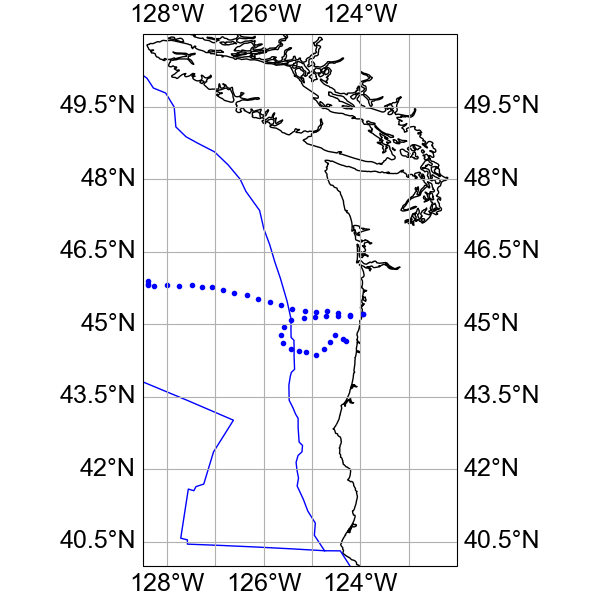

In [25]:
%matplotlib widget

fig = plt.figure(figsize=[6,6],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines()

#ax.plot(grid_df.lon,grid_df.lat,'.')
# ax.plot(north.lon,north.lat,'k.')
# ax.plot(south.lon,south.lat,'k.')
ax.plot(north_nearby_grid.lon,north_nearby_grid.lat,'b.')
ax.plot(south_nearby_grid.lon,south_nearby_grid.lat,'b.')

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
ax.set_xlim(-128.5,-122)
ax.set_ylim(40,51)
gl = ax.gridlines(draw_labels=True) 

In [26]:
nearby_points = pd.concat([north_nearby_grid,south_nearby_grid])

In [27]:
nearby_points = nearby_points[nearby_points.lon>-128]

In [28]:
nearby_points

,station,network,lat,lon,elev,elev1,geometry,station_number,route_distance_m,distance_to_cable_m
0,X075761,CZ,45.20619,-123.95502,0.0,0.0,POINT (-123.95502 45.20619),0,0.000000,1048.078378
1,X075470,CZ,45.18578,-124.20926,0.0,0.0,POINT (-124.20926 45.18578),1,20000.000000,905.759688
2,X076303,CZ,45.23680,-124.46516,0.0,0.0,POINT (-124.46516 45.23680),2,40000.000000,625.217248
3,X076856,CZ,45.26961,-124.69546,0.0,0.0,POINT (-124.69546 45.26961),3,60000.000000,153.590531
4,X076566,CZ,45.24799,-124.92419,0.0,0.0,POINT (-124.92419 45.24799),4,80000.000000,237.990153
5,X077119,CZ,45.27987,-125.15477,0.0,0.0,POINT (-125.15477 45.27987),5,100000.000000,620.390001
6,X077671,CZ,45.31075,-125.41109,0.0,0.0,POINT (-125.41109 45.31075),6,120000.000000,75.733474
7,X079067,CZ,45.39559,-125.64467,0.0,0.0,POINT (-125.64467 45.39559),7,140000.000000,465.088615
8,X080182,CZ,45.46196,-125.87801,0.0,0.0,POINT (-125.87801 45.46196),8,160000.000000,568.877091
9,X081297,CZ,45.52783,-126.11189,0.0,0.0,POINT (-126.11189 45.52783),9,180000.000000,198.763789


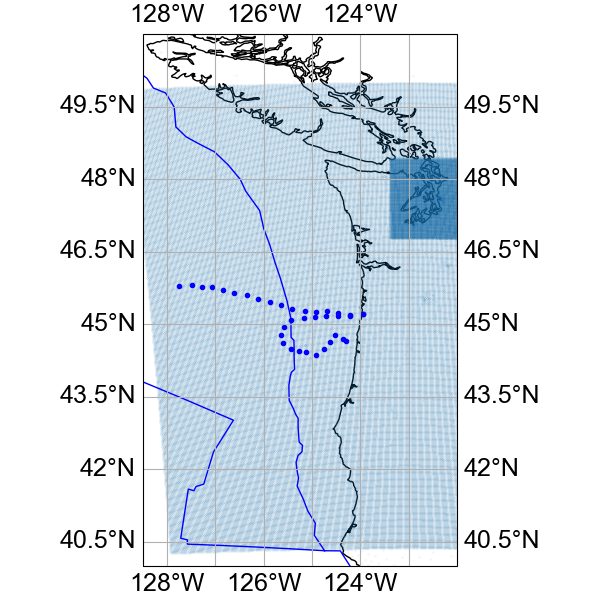

In [29]:
%matplotlib widget

fig = plt.figure(figsize=[6,6],constrained_layout=True)
ax=fig.add_subplot(projection=ccrs.PlateCarree(central_longitude=0))
ax.coastlines()

ax.plot(grid_df.lon,grid_df.lat,'.',markersize=0.1)
# ax.plot(north.lon,north.lat,'k.')
# ax.plot(south.lon,south.lat,'k.')
ax.plot(nearby_points.lon,nearby_points.lat,'b.')

# Plot tectonic plate boundaries from local file
for feature in plate_boundaries['features']:
    coords = feature['geometry']['coordinates']
    if feature['geometry']['type'] == 'LineString':
        lons, lats = zip(*coords)
        ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
    elif feature['geometry']['type'] == 'MultiLineString':
        for line in coords:
            lons, lats = zip(*line)
            ax.plot(lons, lats, color='blue', linewidth=1, transform=ccrs.PlateCarree())
ax.set_xlim(-128.5,-122)
ax.set_ylim(40,51)
gl = ax.gridlines(draw_labels=True) 